In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Simulation finished! Opening interactive 3D window...


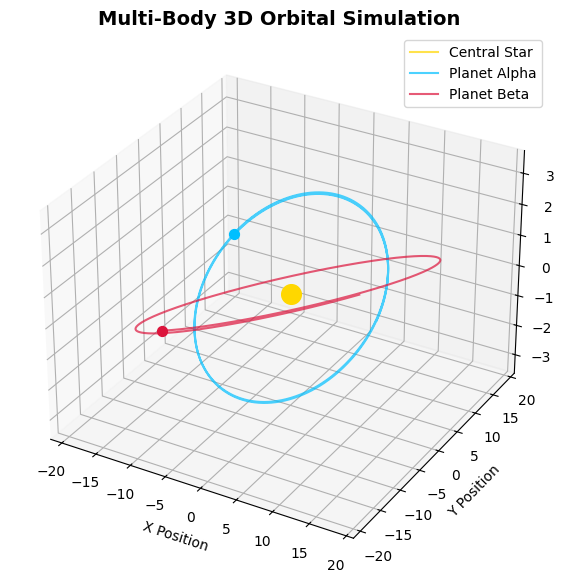

In [4]:
import matplotlib.pyplot as plt

# 1. Define multiple celestial bodies in 3D space
# Each body has position (x,y,z), velocity (vx,vy,vz), mass, and color
bodies = [
    {
        "name": "Central Star", 
        "x": 0.0, "y": 0.0, "z": 0.0, 
        "vx": 0.0, "vy": 0.0, "vz": 0.0, 
        "mass": 1000.0, "color": "gold"
    },
    {
        "name": "Planet Alpha", 
        "x": 12.0, "y": 0.0, "z": 0.0, 
        "vx": 0.0, "vy": 9.0, "vz": 1.5,   # Has a Z velocity to tilt the orbit in 3D
        "mass": 2.0, "color": "deepskyblue"
    },
    {
        "name": "Planet Beta", 
        "x": 0.0, "y": 18.0, "z": -2.0, 
        "vx": -7.5, "vy": 0.0, "vz": -1.0, 
        "mass": 1.0, "color": "crimson"
    }
]

# Set up lists to store the path history for each body
for b in bodies:
    b["path_x"] = []
    b["path_y"] = []
    b["path_z"] = []

# 2. Simulation Settings
G = 1.0         # Gravitational constant
dt = 0.01       # Time step size
steps = 2000    # Total number of simulation loops
softening = 0.1 # Prevents infinite force/crashes during close passes

# 3. The Main Simulation Loop (Multi-Body N-Body Logic)
for step in range(steps):
    
    # Create temporary acceleration lists for this step
    ax = [0.0] * len(bodies)
    ay = [0.0] * len(bodies)
    az = [0.0] * len(bodies)
    
    # Calculate gravitational pull between every pair of bodies
    for i in range(len(bodies)):
        for j in range(len(bodies)):
            if i != j:
                # Distance vector from body i to body j
                dx = bodies[j]["x"] - bodies[i]["x"]
                dy = bodies[j]["y"] - bodies[i]["y"]
                dz = bodies[j]["z"] - bodies[i]["z"]
                
                # Distance squared (with softening to avoid divide-by-zero)
                dist_sq = dx**2 + dy**2 + dz**2 + softening**2
                distance = dist_sq ** 0.5
                
                # Acceleration formula: a = (G * mass_j) / distance^3 * distance_vector
                acc_factor = (G * bodies[j]["mass"]) / (distance**3)
                
                ax[i] += acc_factor * dx
                ay[i] += acc_factor * dy
                az[i] += acc_factor * dz

    # Update velocities and positions for all bodies
    for i in range(len(bodies)):
        # Update speed based on acceleration
        bodies[i]["vx"] += ax[i] * dt
        bodies[i]["vy"] += ay[i] * dt
        bodies[i]["vz"] += az[i] * dt
        
        # Update position based on speed
        bodies[i]["x"] += bodies[i]["vx"] * dt
        bodies[i]["y"] += bodies[i]["vy"] * dt
        bodies[i]["z"] += bodies[i]["vz"] * dt
        
        # Save positions to draw the trail later
        bodies[i]["path_x"].append(bodies[i]["x"])
        bodies[i]["path_y"].append(bodies[i]["y"])
        bodies[i]["path_z"].append(bodies[i]["z"])

# 4. Interactive 3D Visualization
fig = plt.figure(figsize=(9, 7))
ax3d = fig.add_subplot(111, projection='3d')

for b in bodies:
    # Plot the full orbital trail
    ax3d.plot(b["path_x"], b["path_y"], b["path_z"], color=b["color"], label=b["name"], alpha=0.7)
    # Plot final position marker
    marker_size = 200 if b["mass"] > 50 else 50
    ax3d.scatter([b["x"]], [b["y"]], [b["z"]], color=b["color"], s=marker_size)

ax3d.set_title("Multi-Body 3D Orbital Simulation", fontsize=14, fontweight='bold')
ax3d.set_xlabel("X Position")
ax3d.set_ylabel("Y Position")
ax3d.set_zlabel("Z Position")
ax3d.legend()

print("Simulation finished! Opening interactive 3D window...")
plt.show()